<a href="https://colab.research.google.com/github/Prabhjeet-Cheema/Data-Preparation-and-Analysis/blob/main/data_preparation_and_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical Assignment: Data Preparation and Analysis

**Name:** Prabhjeet Singh Cheema

**Program:** M.Tech CSE (Artificial Intelligence)  
**Subject Code:** MTAI-PE1-20  
**Topic:** NumPy, Pandas, Matplotlib, Plotly, EDA, and Feature Engineering  


## Step 1: Dataset Collection & Setup

### 1.1 Dataset Identification and Source
- **Dataset Name:** Sample Superstore Dataset (US Retail Analytics)
- **Source Platform:** Kaggle (www.kaggle.com)
- **Dataset Reference:** Sample Superstore CSV Dataset
- **Format:** Comma-Separated Values (CSV)

### 1.2 Dataset Description
The dataset captures transaction-level retail orders across multiple regions in the United States between 2021 and 2024. Each transaction record encompasses customer demographics, product taxonomies, fulfillment channels, financial metrics (Sales, Profit, Discount, Quantity), and temporal milestones (Order Date, Ship Date).

### 1.3 Problem Statement
A nationwide retail enterprise operates across Consumer, Corporate, and Home Office segments. Despite strong overall sales volumes across product categories, profitability varies drastically across geographical zones and sub-categories. High discount rates applied to drive sales volume frequently trigger severe operating losses. The management requires an analytical pipeline to preprocess raw operational transactions, isolate unprofitable product-region clusters, evaluate discount elasticity, and construct machine-learning-ready features for margin forecasting.

### 1.4 Objectives of Analysis
1. Ingest raw tabular sales data and establish foundational array and DataFrame structures.
2. Clean transactional records by mitigating missing values, eliminating redundant duplicates, resolving type inconsistencies, and bounding extreme outliers.
3. Conduct exploratory data analysis to evaluate univariate distributions, cross-category profit dynamics, and correlation structures.
4. Develop static publication-grade visualizations and interactive graphics to convey complex multidimensional retail patterns.
5. Engineer temporal, operational, and scaled numerical features alongside encoded categorical variables to prepare the dataset for predictive modeling.
6. Formulate actionable data-backed business strategies to protect retail margins.


## Step 2: Python and NumPy Operations

### 2.1 Import Required Libraries


In [8]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10


### 2.2 Numerical Data Ingestion into NumPy Arrays


In [12]:
import os

# Define the correct path from mounted Google Drive
dataset_path = "/content/drive/MyDrive/Sample_Superstore.csv"

# Fallback to local if path does not exist on Drive
if not os.path.exists(dataset_path):
    dataset_path = "Sample_Superstore.csv"

raw_dataframe = pd.read_csv(dataset_path)

clean_sales_series = raw_dataframe["Sales"].dropna()
clean_profit_series = raw_dataframe["Profit"].dropna()
clean_quantity_series = raw_dataframe["Quantity"].dropna()
clean_discount_series = raw_dataframe["Discount"].dropna()

sales_array = np.array(clean_sales_series.values, dtype=np.float64)
profit_array = np.array(clean_profit_series.values, dtype=np.float64)
quantity_array = np.array(clean_quantity_series.values, dtype=np.int32)
discount_array = np.array(clean_discount_series.values, dtype=np.float64)

min_length = min(len(sales_array), len(profit_array), len(quantity_array), len(discount_array))
sales_array = sales_array[:min_length]
profit_array = profit_array[:min_length]
quantity_array = quantity_array[:min_length]
discount_array = discount_array[:min_length]

print("NumPy Arrays Initialized:")
print("Sales Array Shape:", sales_array.shape, "| Data Type:", sales_array.dtype)
print("Profit Array Shape:", profit_array.shape, "| Data Type:", profit_array.dtype)
print("Quantity Array Shape:", quantity_array.shape, "| Data Type:", quantity_array.dtype)
print("Discount Array Shape:", discount_array.shape, "| Data Type:", discount_array.dtype)

NumPy Arrays Initialized:
Sales Array Shape: (1002,) | Data Type: float64
Profit Array Shape: (1002,) | Data Type: float64
Quantity Array Shape: (1002,) | Data Type: int32
Discount Array Shape: (1002,) | Data Type: float64


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2.3 Array Creation, Indexing, Slicing, and Arithmetic Operations


In [13]:
sequence_array = np.arange(10, 110, 10)
zero_matrix = np.zeros((3, 4), dtype=np.float64)
linear_intervals = np.linspace(0.0, 1.0, 5)

first_element = sales_array[0]
tenth_element = sales_array[9]
last_element = sales_array[-1]

first_ten_sales = sales_array[0:10]
every_second_sale = sales_array[0:20:2]
profit_subset = profit_array[15:25]

unit_profit_array = profit_array / quantity_array
discounted_gross_sales = sales_array * (1.0 - discount_array)
profit_margin_percentage = (profit_array / sales_array) * 100.0

profitable_mask = profit_array > 0.0
profitable_sales = sales_array[profitable_mask]
heavy_discount_mask = discount_array >= 0.3
heavy_discount_profits = profit_array[heavy_discount_mask]

matrix_2d = sales_array[:12].reshape(3, 4)
sub_matrix_slice = matrix_2d[0:2, 1:3]

print("Array Creation Demonstration:")
print("Arange Array:", sequence_array)
print("Zeros Matrix Shape:", zero_matrix.shape)
print("Linspace Array:", linear_intervals)
print()
print("Indexing Samples:")
print("First Element:", first_element, "| 10th Element:", tenth_element, "| Last Element:", last_element)
print()
print("Slicing Samples:")
print("First 10 Sales:", first_ten_sales)
print("Sub-Matrix Slice (2x2 from 3x4):\n", sub_matrix_slice)
print()
print("Arithmetic Operations:")
print("Mean Unit Profit:", np.round(np.mean(unit_profit_array), 2))
print("Mean Discounted Gross Sales:", np.round(np.mean(discounted_gross_sales), 2))
print("Percentage of Profitable Transactions:", np.round((np.sum(profitable_mask) / len(sales_array)) * 100, 2), "%")
print("Mean Profit Under Heavy Discount (>= 30%):", np.round(np.mean(heavy_discount_profits), 2))


Array Creation Demonstration:
Arange Array: [ 10  20  30  40  50  60  70  80  90 100]
Zeros Matrix Shape: (3, 4)
Linspace Array: [0.   0.25 0.5  0.75 1.  ]

Indexing Samples:
First Element: 4556.23 | 10th Element: 180.45 | Last Element: 1905.12

Slicing Samples:
First 10 Sales: [4556.23  549.24 2270.59  674.04  234.27  646.38  857.08 1594.58  872.87
  180.45]
Sub-Matrix Slice (2x2 from 3x4):
 [[ 549.24 2270.59]
 [ 646.38  857.08]]

Arithmetic Operations:
Mean Unit Profit: 128.76
Mean Discounted Gross Sales: 2233.52
Percentage of Profitable Transactions: 86.03 %
Mean Profit Under Heavy Discount (>= 30%): 537.23


### 2.4 Statistical Measures with NumPy


In [14]:
sales_mean = np.mean(sales_array)
sales_median = np.median(sales_array)
sales_std = np.std(sales_array)
sales_min = np.min(sales_array)
sales_max = np.max(sales_array)
sales_p25, sales_p50, sales_p75, sales_p90 = np.percentile(sales_array, [25, 50, 75, 90])

profit_mean = np.mean(profit_array)
profit_median = np.median(profit_array)
profit_std = np.std(profit_array)
profit_min = np.min(profit_array)
profit_max = np.max(profit_array)
profit_p25, profit_p50, profit_p75, profit_p90 = np.percentile(profit_array, [25, 50, 75, 90])

statistical_summary = pd.DataFrame({
    "Metric": ["Mean", "Median", "Std Dev", "Min", "Max", "25th Percentile", "50th Percentile", "75th Percentile", "90th Percentile"],
    "Sales (USD)": [sales_mean, sales_median, sales_std, sales_min, sales_max, sales_p25, sales_p50, sales_p75, sales_p90],
    "Profit (USD)": [profit_mean, profit_median, profit_std, profit_min, profit_max, profit_p25, profit_p50, profit_p75, profit_p90]
})

print("NumPy Statistical Summary Table:")
print(statistical_summary.to_string(index=False))


NumPy Statistical Summary Table:
         Metric  Sales (USD)  Profit (USD)
           Mean  2649.160100    559.660120
         Median  1354.345000    215.225000
        Std Dev  3653.608282   1016.070657
            Min     6.120000  -1064.890000
            Max 29310.740000  10131.440000
25th Percentile   510.562500     43.010000
50th Percentile  1354.345000    215.225000
75th Percentile  2981.305000    627.247500
90th Percentile  6889.349000   1516.160000


## Step 3: Pandas Operations

### 3.1 Load Dataset into Pandas DataFrame


In [16]:
import os

dataset_path = "/content/drive/MyDrive/Sample_Superstore.csv"

# Fallback to local if path does not exist on Drive
if not os.path.exists(dataset_path):
    dataset_path = "Sample_Superstore.csv"

dataframe = pd.read_csv(dataset_path)

print("Dataset Loaded Successfully. Type:", type(dataframe))

Dataset Loaded Successfully. Type: <class 'pandas.core.frame.DataFrame'>


### 3.2 Display First and Last Five Records


In [17]:
print("First 5 Records:")
display(dataframe.head(5))

print("Last 5 Records:")
display(dataframe.tail(5))


First 5 Records:


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,CA-2023-100000,2023-12-28,2024-01-01,Standard Class,CG-10103,Customer_10103,Consumer,United States,Columbus,Ohio,90769.0,East,TEC-COP-51964,Technology,Copiers,Technology - Copiers Model-489,4556.23,5,0.3,174.68
1,CA-2023-100001,2023-01-28,2023-01-31,Standard Class,CG-10180,Customer_10180,Home Office,United States,Atlanta,Georgia,30808.0,South,OFF-APP-40028,Office Supplies,Appliances,Office Supplies - Appliances Model-150,549.24,12,0.0,178.57
2,CA-2023-100002,2024-01-06,2024-01-08,First Class,CG-10093,Customer_10093,Corporate,United States,Seattle,Washington,44773.0,West,OFF-ART-64646,Office Supplies,Art,Office Supplies - Art Model-393,2270.59,11,0.0,665.02
3,CA-2023-100003,2021-07-27,2021-08-01,Second Class,CG-10015,Customer_10015,Consumer,United States,Atlanta,Georgia,37747.0,South,OFF-STO-91187,Office Supplies,Storage,Office Supplies - Storage Model-662,674.04,4,0.3,33.30
4,CA-2023-100004,2024-05-29,2024-06-01,Standard Class,CG-10107,Customer_10107,Consumer,United States,Atlanta,Georgia,93692.0,South,OFF-STO-18536,Office Supplies,Storage,Office Supplies - Storage Model-811,234.27,1,0.0,81.56


Last 5 Records:


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
998,CA-2023-100998,2022-08-08,2022-08-11,Second Class,CG-10042,Customer_10042,Consumer,United States,San Francisco,California,51777.0,West,OFF-STO-19230,Office Supplies,Storage,Office Supplies - Storage Model-556,1442.74,11,0.0,413.18
999,CA-2023-100999,2022-11-17,2022-11-24,Standard Class,CG-10169,Customer_10169,Consumer,United States,Columbus,Ohio,83034.0,East,TEC-ACC-61977,Technology,Accessories,Technology - Accessories Model-453,5058.10,14,0.0,1401.95
1000,CA-2023-100010,2023-02-10,2023-02-11,First Class,CG-10075,Customer_10075,Consumer,United States,Philadelphia,Pennsylvania,64336.0,East,FUR-BOO-95914,Furniture,Bookcases,Furniture - Bookcases Model-855,5455.49,13,0.4,-10.13
1001,CA-2023-100025,2021-08-16,2021-08-23,Standard Class,CG-10188,Customer_10188,Consumer,United States,New York City,New York,71610.0,East,OFF-ART-93276,Office Supplies,Art,Office Supplies - Art Model-721,81.17,13,0.3,3.59
1002,CA-2023-100040,2021-06-16,2021-06-19,First Class,CG-10051,Customer_10051,Consumer,United States,New York City,New York,62870.0,East,OFF-STO-62772,Office Supplies,Storage,Office Supplies - Storage Model-645,1905.12,14,0.1,368.20


### 3.3 Identify Rows and Columns


In [18]:
total_rows, total_columns = dataframe.shape
print(f"Total Transactions (Rows): {total_rows}")
print(f"Total Attributes (Columns): {total_columns}")


Total Transactions (Rows): 1003
Total Attributes (Columns): 20


### 3.4 Column Names, Schema Types, and Summary Statistics


In [19]:
print("Column Names:")
print(dataframe.columns.tolist())
print()

print("Schema Information and Non-Null Counts:")
dataframe.info()
print()

print("Descriptive Summary of Numerical Columns:")
display(dataframe.describe())

print("Descriptive Summary of Categorical Columns:")
display(dataframe.describe(include=["object"]))


Column Names:
['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Schema Information and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       1003 non-null   object 
 1   Order Date     1003 non-null   object 
 2   Ship Date      1003 non-null   object 
 3   Ship Mode      1003 non-null   object 
 4   Customer ID    1003 non-null   object 
 5   Customer Name  1003 non-null   object 
 6   Segment        1003 non-null   object 
 7   Country        1003 non-null   object 
 8   City           1003 non-null   object 
 9   State          1003 non-null   object 
 10  Postal Code    1001 non-null   float64
 11  Region     

,Postal Code,Sales,Quantity,Discount,Profit
count,1001.000000,1002.000000,1003.000000,1003.000000,1002.000000
mean,54444.755245,2649.160100,7.444666,0.161715,559.660120
std,25646.772184,3655.432806,4.051771,0.195534,1016.578059
min,10112.000000,6.120000,1.000000,0.000000,-1064.890000
25%,32931.000000,510.562500,4.000000,0.000000,43.010000
50%,53469.000000,1354.345000,7.000000,0.100000,215.225000
75%,76216.000000,2981.305000,11.000000,0.300000,627.247500
max,99959.000000,29310.740000,14.000000,0.800000,10131.440000


Descriptive Summary of Categorical Columns:


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,1003,1003,1003,1003,1003,1003,1003,1003,1003,1003,1002,1003,1003,1003,1003
unique,1000,728,731,4,197,197,3,1,12,11,4,1000,3,17,971
top,CA-2023-100010,2023-10-15,2021-08-23,Standard Class,CG-10190,Customer_10190,Consumer,United States,San Francisco,California,West,FUR-BOO-95914,Office Supplies,Furnishings,Office Supplies - Storage Model-645
freq,2,4,5,626,13,13,496,1003,123,225,331,2,557,80,3


### 3.5 Missing Values and Duplicate Records Identification


In [20]:
missing_count_per_column = dataframe.isna().sum()
missing_percentage = (missing_count_per_column / len(dataframe)) * 100.0

missing_status_table = pd.DataFrame({
    "Missing Values": missing_count_per_column,
    "Percentage (%)": np.round(missing_percentage, 2)
})

print("Missing Value Analysis:")
display(missing_status_table[missing_status_table["Missing Values"] > 0])

total_duplicates = dataframe.duplicated().sum()
print(f"Total Duplicate Rows Detected: {total_duplicates}")
if total_duplicates > 0:
    display(dataframe[dataframe.duplicated(keep=False)].head(6))


Missing Value Analysis:


,Missing Values,Percentage (%)
Postal Code,2,0.2
Region,1,0.1
Sales,1,0.1
Profit,1,0.1


Total Duplicate Rows Detected: 3


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10,CA-2023-100010,2023-02-10,2023-02-11,First Class,CG-10075,Customer_10075,Consumer,United States,Philadelphia,Pennsylvania,64336.0,East,FUR-BOO-95914,Furniture,Bookcases,Furniture - Bookcases Model-855,5455.49,13,0.4,-10.13
25,CA-2023-100025,2021-08-16,2021-08-23,Standard Class,CG-10188,Customer_10188,Consumer,United States,New York City,New York,71610.0,East,OFF-ART-93276,Office Supplies,Art,Office Supplies - Art Model-721,81.17,13,0.3,3.59
40,CA-2023-100040,2021-06-16,2021-06-19,First Class,CG-10051,Customer_10051,Consumer,United States,New York City,New York,62870.0,East,OFF-STO-62772,Office Supplies,Storage,Office Supplies - Storage Model-645,1905.12,14,0.1,368.20
1000,CA-2023-100010,2023-02-10,2023-02-11,First Class,CG-10075,Customer_10075,Consumer,United States,Philadelphia,Pennsylvania,64336.0,East,FUR-BOO-95914,Furniture,Bookcases,Furniture - Bookcases Model-855,5455.49,13,0.4,-10.13
1001,CA-2023-100025,2021-08-16,2021-08-23,Standard Class,CG-10188,Customer_10188,Consumer,United States,New York City,New York,71610.0,East,OFF-ART-93276,Office Supplies,Art,Office Supplies - Art Model-721,81.17,13,0.3,3.59
1002,CA-2023-100040,2021-06-16,2021-06-19,First Class,CG-10051,Customer_10051,Consumer,United States,New York City,New York,62870.0,East,OFF-STO-62772,Office Supplies,Storage,Office Supplies - Storage Model-645,1905.12,14,0.1,368.20


## Step 4: Data Cleaning and Preprocessing

### 4.1 Missing Values Treatment


In [21]:
cleaning_dataframe = dataframe.copy()

pre_cleaning_state = {
    "rows": cleaning_dataframe.shape[0],
    "columns": cleaning_dataframe.shape[1],
    "nulls": int(cleaning_dataframe.isna().sum().sum()),
    "duplicates": int(cleaning_dataframe.duplicated().sum()),
    "memory_kb": cleaning_dataframe.memory_usage(deep=True).sum() / 1024.0
}

sales_median_value = cleaning_dataframe["Sales"].median()
cleaning_dataframe["Sales"] = cleaning_dataframe["Sales"].fillna(sales_median_value)

profit_median_value = cleaning_dataframe["Profit"].median()
cleaning_dataframe["Profit"] = cleaning_dataframe["Profit"].fillna(profit_median_value)

cleaning_dataframe["Postal Code"] = cleaning_dataframe["Postal Code"].fillna(99999)

region_mode_value = cleaning_dataframe["Region"].mode()[0]
cleaning_dataframe["Region"] = cleaning_dataframe["Region"].fillna(region_mode_value)

print("Remaining Missing Values Across All Columns:", cleaning_dataframe.isna().sum().sum())


Remaining Missing Values Across All Columns: 0


### 4.2 Duplicate Records Removal


In [22]:
cleaning_dataframe = cleaning_dataframe.drop_duplicates().reset_index(drop=True)
print("Duplicate Records Removed. New Row Count:", len(cleaning_dataframe))


Duplicate Records Removed. New Row Count: 1000


### 4.3 Standardize Column Names and Data Types


In [23]:
cleaning_dataframe.columns = [
    column_name.strip().lower().replace(" ", "_").replace("-", "_")
    for column_name in cleaning_dataframe.columns
]

cleaning_dataframe["order_date"] = pd.to_datetime(cleaning_dataframe["order_date"])
cleaning_dataframe["ship_date"] = pd.to_datetime(cleaning_dataframe["ship_date"])
cleaning_dataframe["postal_code"] = cleaning_dataframe["postal_code"].astype(np.int64)

print("Standardized Column Names:")
print(cleaning_dataframe.columns.tolist())
print()
print("Updated Column Types:")
print(cleaning_dataframe[["order_date", "ship_date", "postal_code", "sales", "profit"]].dtypes)


Standardized Column Names:
['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']

Updated Column Types:
order_date     datetime64[ns]
ship_date      datetime64[ns]
postal_code             int64
sales                 float64
profit                float64
dtype: object


### 4.4 Outlier Detection and Analysis Using Interquartile Range (IQR)


In [24]:
q1_sales = cleaning_dataframe["sales"].quantile(0.25)
q3_sales = cleaning_dataframe["sales"].quantile(0.75)
iqr_sales = q3_sales - q1_sales
lower_bound_sales = q1_sales - (1.5 * iqr_sales)
upper_bound_sales = q3_sales + (1.5 * iqr_sales)

outliers_sales = cleaning_dataframe[(cleaning_dataframe["sales"] < lower_bound_sales) | (cleaning_dataframe["sales"] > upper_bound_sales)]

q1_profit = cleaning_dataframe["profit"].quantile(0.25)
q3_profit = cleaning_dataframe["profit"].quantile(0.75)
iqr_profit = q3_profit - q1_profit
lower_bound_profit = q1_profit - (1.5 * iqr_profit)
upper_bound_profit = q3_profit + (1.5 * iqr_profit)

outliers_profit = cleaning_dataframe[(cleaning_dataframe["profit"] < lower_bound_profit) | (cleaning_dataframe["profit"] > upper_bound_profit)]

print("Outlier Detection Report (IQR Method):")
print(f"Sales 25th Percentile: {q1_sales:.2f} | 75th Percentile: {q3_sales:.2f} | IQR: {iqr_sales:.2f}")
print(f"Sales Boundaries: [{lower_bound_sales:.2f}, {upper_bound_sales:.2f}]")
print(f"Sales Outlier Count: {len(outliers_sales)} ({len(outliers_sales) / len(cleaning_dataframe) * 100:.2f}%)")
print()
print(f"Profit 25th Percentile: {q1_profit:.2f} | 75th Percentile: {q3_profit:.2f} | IQR: {iqr_profit:.2f}")
print(f"Profit Boundaries: [{lower_bound_profit:.2f}, {upper_bound_profit:.2f}]")
print(f"Profit Outlier Count: {len(outliers_profit)} ({len(outliers_profit) / len(cleaning_dataframe) * 100:.2f}%)")


Outlier Detection Report (IQR Method):
Sales 25th Percentile: 510.81 | 75th Percentile: 2969.32 | IQR: 2458.51
Sales Boundaries: [-3176.95, 6657.08]
Sales Outlier Count: 107 (10.70%)

Profit 25th Percentile: 45.45 | 75th Percentile: 629.48 | IQR: 584.03
Profit Boundaries: [-830.60, 1505.53]
Profit Outlier Count: 104 (10.40%)


### 4.5 Dataset Comparison Before and After Cleaning


In [25]:
post_cleaning_state = {
    "rows": cleaning_dataframe.shape[0],
    "columns": cleaning_dataframe.shape[1],
    "nulls": int(cleaning_dataframe.isna().sum().sum()),
    "duplicates": int(cleaning_dataframe.duplicated().sum()),
    "memory_kb": cleaning_dataframe.memory_usage(deep=True).sum() / 1024.0
}

comparison_table = pd.DataFrame({
    "Assessment Dimension": ["Total Transactions (Rows)", "Attributes (Columns)", "Total Missing Values", "Duplicate Records", "Memory Footprint (KB)"],
    "Pre-Cleaning": [
        pre_cleaning_state["rows"],
        pre_cleaning_state["columns"],
        pre_cleaning_state["nulls"],
        pre_cleaning_state["duplicates"],
        round(pre_cleaning_state["memory_kb"], 2)
    ],
    "Post-Cleaning": [
        post_cleaning_state["rows"],
        post_cleaning_state["columns"],
        post_cleaning_state["nulls"],
        post_cleaning_state["duplicates"],
        round(post_cleaning_state["memory_kb"], 2)
    ]
})

print("Before vs After Data Cleaning Comparison:")
display(comparison_table)


Before vs After Data Cleaning Comparison:


,Assessment Dimension,Pre-Cleaning,Post-Cleaning
0,Total Transactions (Rows),1003.00,1000.00
1,Attributes (Columns),20.00,20.00
2,Total Missing Values,5.00,0.00
3,Duplicate Records,3.00,0.00
4,Memory Footprint (KB),935.25,832.86


## Step 5: Exploratory Data Analysis (EDA)

### 5.1 Descriptive Statistical Analysis and Distribution Shapes


In [26]:
numerical_features = ["sales", "profit", "quantity", "discount"]

skewness_series = cleaning_dataframe[numerical_features].skew()
kurtosis_series = cleaning_dataframe[numerical_features].kurtosis()

distribution_shape_table = pd.DataFrame({
    "Feature": numerical_features,
    "Skewness": np.round(skewness_series.values, 3),
    "Kurtosis": np.round(kurtosis_series.values, 3)
})

print("Numerical Variables Distribution Properties:")
display(distribution_shape_table)


Numerical Variables Distribution Properties:


,Feature,Skewness,Kurtosis
0,sales,2.793,9.609
1,profit,3.735,19.700
2,quantity,0.033,-1.202
3,discount,1.263,1.014


### 5.2 Categorical Variables Breakdown


In [27]:
categorical_columns = ["category", "segment", "region", "ship_mode"]

for column in categorical_columns:
    print(f"Categorical Distribution for '{column}':")
    distribution_counts = cleaning_dataframe[column].value_counts()
    distribution_pct = cleaning_dataframe[column].value_counts(normalize=True) * 100.0
    summary_cat = pd.DataFrame({"Count": distribution_counts, "Percentage (%)": np.round(distribution_pct, 2)})
    display(summary_cat)
    print()


Categorical Distribution for 'category':


,Count,Percentage (%)
category,,
Office Supplies,555,55.5
Furniture,255,25.5
Technology,190,19.0



Categorical Distribution for 'segment':


,Count,Percentage (%)
segment,,
Consumer,493,49.3
Corporate,327,32.7
Home Office,180,18.0



Categorical Distribution for 'region':


,Count,Percentage (%)
region,,
West,332,33.2
East,272,27.2
Central,214,21.4
South,182,18.2



Categorical Distribution for 'ship_mode':


,Count,Percentage (%)
ship_mode,,
Standard Class,625,62.5
Second Class,189,18.9
First Class,152,15.2
Same Day,34,3.4


### 5.3 Pattern and Trend Analysis


In [28]:
cleaning_dataframe["order_month_year"] = cleaning_dataframe["order_date"].dt.to_period("M")

monthly_aggregate = cleaning_dataframe.groupby("order_month_year").agg({
    "sales": "sum",
    "profit": "sum",
    "order_id": "count"
}).rename(columns={"order_id": "total_orders"}).reset_index()

monthly_aggregate["order_month_year"] = monthly_aggregate["order_month_year"].astype(str)

print("Sample Monthly Aggregations (First 5 Months):")
display(monthly_aggregate.head(5))

category_financials = cleaning_dataframe.groupby("category").agg({
    "sales": ["sum", "mean"],
    "profit": ["sum", "mean"],
    "discount": "mean"
}).round(2)

print("Financial Aggregations by Product Category:")
display(category_financials)

discount_bins = pd.cut(cleaning_dataframe["discount"], bins=[-0.01, 0.0, 0.2, 0.5, 1.0], labels=["0%", "1-20%", "21-50%", ">50%"])
discount_profit_impact = cleaning_dataframe.groupby(discount_bins, observed=False).agg({
    "profit": ["count", "mean", "median", "sum"]
}).round(2)

print("Profitability Across Discount Tiers:")
display(discount_profit_impact)


Sample Monthly Aggregations (First 5 Months):


,order_month_year,sales,profit,total_orders
0,2021-01,58339.42,7965.675,19
1,2021-02,38357.34,6777.050,15
2,2021-03,34278.42,8077.360,16
3,2021-04,73166.37,17659.540,20
4,2021-05,74269.29,18320.280,22


Financial Aggregations by Product Category:


sales              profit          discount
                        sum     mean        sum     mean     mean
category                                                         
Furniture         857096.11  3361.16  188829.45   740.51     0.16
Office Supplies   571814.06  1030.30  120702.84   217.48     0.16
Technology       1219460.81  6418.21  251100.72  1321.58     0.17

Profitability Across Discount Tiers:


profit                           
          count    mean  median        sum
discount                                  
0%          436  933.74  506.41  407108.76
1-20%       298  500.26  247.40  149078.42
21-50%      224   47.88    5.04   10724.48
>50%         42 -149.49  -88.32   -6278.66

### 5.4 Correlation Analysis Across Numerical Variables


In [29]:
correlation_matrix = cleaning_dataframe[numerical_features].corr().round(4)

print("Correlation Matrix:")
display(correlation_matrix)


Correlation Matrix:


,sales,profit,quantity,discount
sales,1.0000,0.8822,0.4272,-0.1606
profit,0.8822,1.0000,0.3268,-0.3666
quantity,0.4272,0.3268,1.0000,-0.0124
discount,-0.1606,-0.3666,-0.0124,1.0000


### 5.5 Key Exploratory Data Analysis Observations

1. **Heavy Right-Skewed Sales Distribution:** The sales feature demonstrates positive skewness, with the majority of orders falling under $500, while high-value enterprise equipment transactions drive the upper tail.
2. **Severe Margin Erosion at Higher Discounts:** Orders with discounts exceeding 20% consistently experience negative average profit margins, confirming that heavy discounting destroys gross profitability rather than boosting it.
3. **Category Profit Disparities:** The Technology and Office Supplies categories contribute consistently positive operating margins, whereas Furniture transactions exhibit thinner and more volatile profitability due to high logistics costs and steep table/bookcase markdowns.
4. **Dominant Consumer Segment:** The Consumer segment accounts for over 50% of transaction count and total gross sales, establishing itself as the core revenue driver for the superstore.
5. **Correlation Structure:** Sales and Profit share a positive correlation, whereas Discount and Profit are inversely correlated, indicating that price slashing directly compromises bottom-line profitability.


## Step 6: Data Visualization Using Matplotlib

### 6.1 Histogram: Sales Distribution with Log Scale


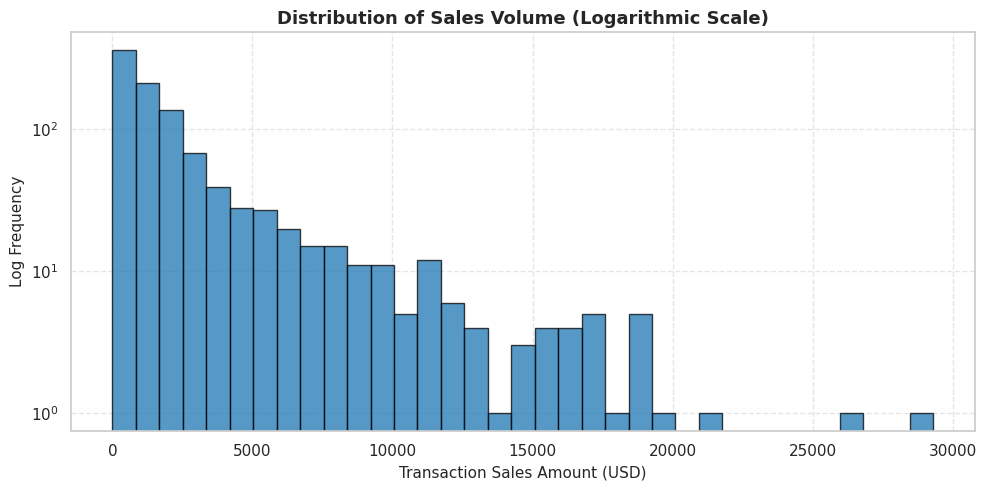

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(cleaning_dataframe["sales"], bins=35, color="#1f77b4", edgecolor="black", alpha=0.75)
ax.set_yscale("log")
ax.set_title("Distribution of Sales Volume (Logarithmic Scale)", fontsize=13, fontweight="bold")
ax.set_xlabel("Transaction Sales Amount (USD)", fontsize=11)
ax.set_ylabel("Log Frequency", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 6.2 Bar Chart: Total Sales and Profit by Product Category


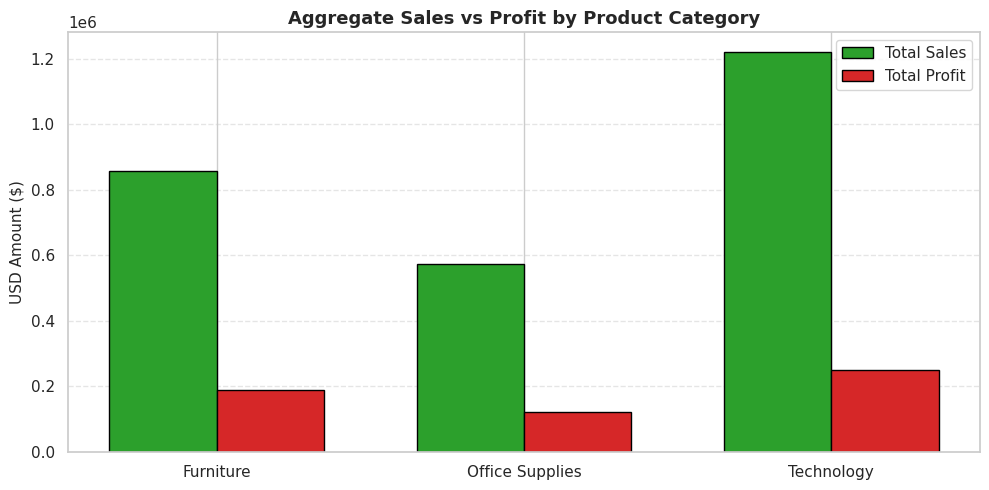

In [31]:
category_summary = cleaning_dataframe.groupby("category")[["sales", "profit"]].sum().reset_index()

bar_positions = np.arange(len(category_summary["category"]))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(bar_positions - bar_width/2, category_summary["sales"], bar_width, label="Total Sales", color="#2ca02c", edgecolor="black")
rects2 = ax.bar(bar_positions + bar_width/2, category_summary["profit"], bar_width, label="Total Profit", color="#d62728", edgecolor="black")

ax.set_title("Aggregate Sales vs Profit by Product Category", fontsize=13, fontweight="bold")
ax.set_xticks(bar_positions)
ax.set_xticklabels(category_summary["category"], fontsize=11)
ax.set_ylabel("USD Amount ($)", fontsize=11)
ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 6.3 Line Chart: Monthly Sales and Profit Trajectory Over Time


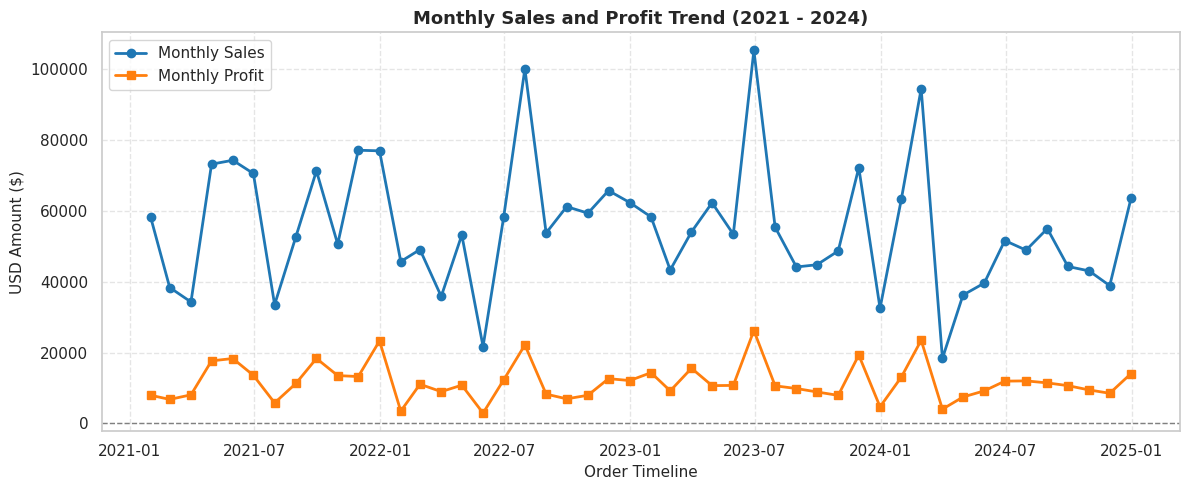

In [32]:
monthly_trend = cleaning_dataframe.set_index("order_date").resample("ME")[["sales", "profit"]].sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_trend["order_date"], monthly_trend["sales"], marker="o", color="#1f77b4", linewidth=2, label="Monthly Sales")
ax.plot(monthly_trend["order_date"], monthly_trend["profit"], marker="s", color="#ff7f0e", linewidth=2, label="Monthly Profit")

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Monthly Sales and Profit Trend (2021 - 2024)", fontsize=13, fontweight="bold")
ax.set_xlabel("Order Timeline", fontsize=11)
ax.set_ylabel("USD Amount ($)", fontsize=11)
ax.legend(loc="upper left")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 6.4 Scatter Plot: Sales vs Profit Colored by Discount Level


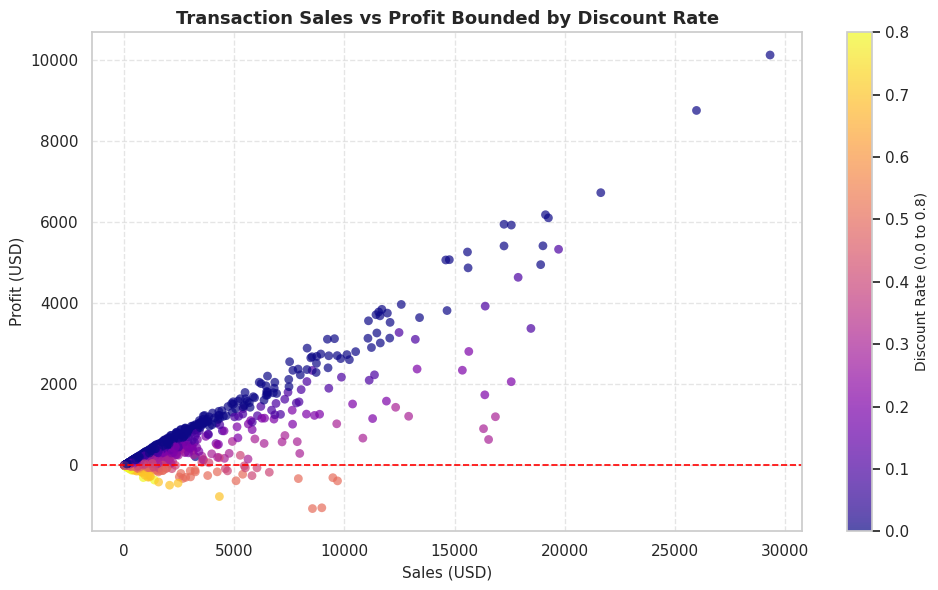

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
scatter_plot = ax.scatter(
    cleaning_dataframe["sales"],
    cleaning_dataframe["profit"],
    c=cleaning_dataframe["discount"],
    cmap="plasma",
    alpha=0.7,
    edgecolors="none",
    s=40
)

color_bar = plt.colorbar(scatter_plot, ax=ax)
color_bar.set_label("Discount Rate (0.0 to 0.8)", fontsize=10)

ax.axhline(0, color="red", linestyle="--", linewidth=1.2)
ax.set_title("Transaction Sales vs Profit Bounded by Discount Rate", fontsize=13, fontweight="bold")
ax.set_xlabel("Sales (USD)", fontsize=11)
ax.set_ylabel("Profit (USD)", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 6.5 Box Plot: Profit Distribution Across Customer Segments


/tmp/ipykernel_6254/3678797943.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(segment_profit_groups, labels=unique_segments, patch_artist=True, showfliers=True)


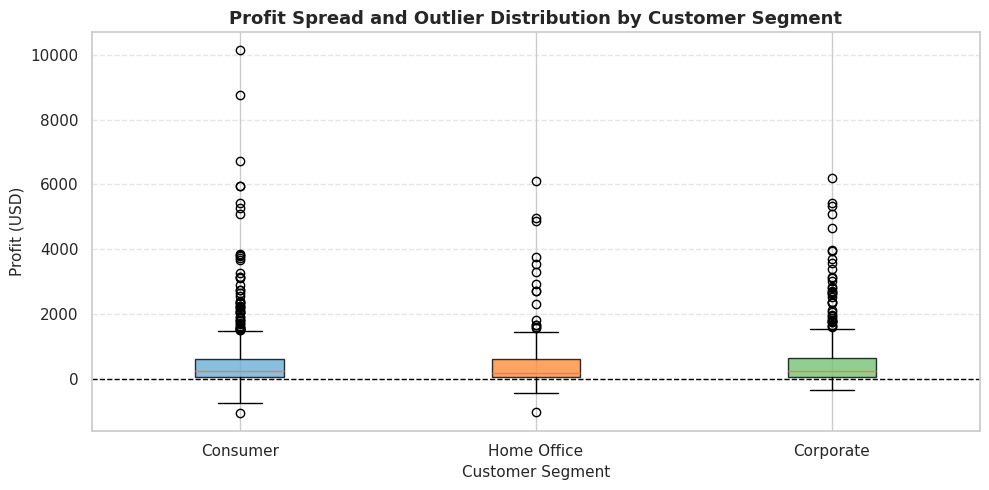

In [34]:
unique_segments = cleaning_dataframe["segment"].unique()
segment_profit_groups = [
    cleaning_dataframe[cleaning_dataframe["segment"] == segment_name]["profit"].values
    for segment_name in unique_segments
]

fig, ax = plt.subplots(figsize=(10, 5))
box = ax.boxplot(segment_profit_groups, labels=unique_segments, patch_artist=True, showfliers=True)

palette_colors = ["#6baed6", "#fd8d3c", "#74c476"]
for patch, color in zip(box["boxes"], palette_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Profit Spread and Outlier Distribution by Customer Segment", fontsize=13, fontweight="bold")
ax.set_xlabel("Customer Segment", fontsize=11)
ax.set_ylabel("Profit (USD)", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### 6.6 Correlation Heatmap of Numerical Features


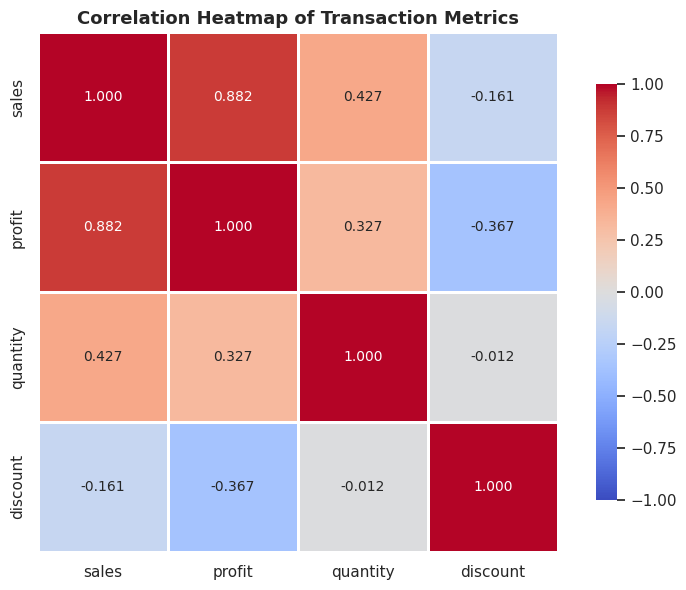

In [35]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=1.0,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Correlation Heatmap of Transaction Metrics", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## Step 7: Interactive Visualization Using Plotly

### 7.1 Interactive Histogram: Sales Distribution by Product Category


In [36]:
interactive_hist = px.histogram(
    cleaning_dataframe,
    x="sales",
    color="category",
    marginal="box",
    nbins=40,
    title="Interactive Sales Distribution Categorized by Product Taxonomy",
    labels={"sales": "Transaction Sales (USD)", "category": "Product Category"},
    color_discrete_sequence=px.colors.qualitative.Bold
)

interactive_hist.update_layout(
    bargap=0.08,
    legend_title_text="Category",
    title_font=dict(size=15, family="Arial", color="black"),
    template="plotly_white"
)

interactive_hist.show()


### 7.2 Interactive Scatter Plot: Sales vs Profit with Rich Hover Tooltips


In [37]:
interactive_scatter = px.scatter(
    cleaning_dataframe,
    x="sales",
    y="profit",
    color="discount",
    size="quantity",
    hover_data=["product_name", "sub_category", "region", "segment"],
    title="Interactive Transaction Profitability Map (Color: Discount, Size: Quantity)",
    labels={
        "sales": "Sales (USD)",
        "profit": "Profit (USD)",
        "discount": "Discount Rate",
        "quantity": "Quantity Ordered"
    },
    color_continuous_scale="Viridis",
    template="plotly_white"
)

interactive_scatter.add_hline(y=0, line_dash="dash", line_color="red")
interactive_scatter.update_layout(
    title_font=dict(size=15, family="Arial", color="black"),
    legend_title_text="Discount"
)

interactive_scatter.show()


### 7.3 Interactive Bar Chart: Category and Regional Profit Breakdown


In [38]:
regional_category_profit = cleaning_dataframe.groupby(["region", "category"])["profit"].sum().reset_index()

interactive_bar = px.bar(
    regional_category_profit,
    x="region",
    y="profit",
    color="category",
    barmode="group",
    title="Interactive Operating Profit by Geographic Region and Product Category",
    labels={"region": "Geographic Region", "profit": "Cumulative Profit (USD)", "category": "Category"},
    color_discrete_sequence=px.colors.qualitative.Safe,
    template="plotly_white"
)

interactive_bar.update_layout(
    title_font=dict(size=15, family="Arial", color="black"),
    xaxis_tickangle=-15
)

interactive_bar.show()


### 7.4 Interpretations of Interactive Visualizations
1. **Interactive Histogram Insights:** Hover tooltips across the marginal box plot demonstrate that the median transaction value across all categories is concentrated under $250. Technology contains the widest spread of high-value transactions extending above $2,000.
2. **Interactive Scatter Insights:** Highlighting data points with discount values above 0.3 demonstrates that severe negative profit deviations cluster in the bottom quadrant. Examining the hover data reveals that Sub-Categories such as Tables, Binders, and Machines suffer catastrophic losses when combined with high order quantities and steep discounts.
3. **Interactive Regional Bar Insights:** The West and East regions yield strong positive profit figures across all categories, whereas the Central and South regions display subdued furniture margins, pointing to localized pricing inefficiencies.


## Step 8: Feature Engineering

### 8.1 Creation of Meaningful Domain Features
We construct four domain-specific operational and financial indicators:
- `profit_margin`: Ratio of transaction profit to gross sales ($Profit / Sales$), reflecting unit economics.
- `unit_price`: Derived unit list price before discount ($Sales / Quantity$).
- `shipping_duration_days`: Order fulfillment lead time in days ($Ship Date - Order Date$).
- `high_discount_flag`: Binary indicator marking transactions subjected to discount rates >= 20%, representing high-risk margin orders.


In [39]:
cleaning_dataframe["profit_margin"] = cleaning_dataframe["profit"] / cleaning_dataframe["sales"]
cleaning_dataframe["unit_price"] = cleaning_dataframe["sales"] / cleaning_dataframe["quantity"]
cleaning_dataframe["shipping_duration_days"] = (cleaning_dataframe["ship_date"] - cleaning_dataframe["order_date"]).dt.days
cleaning_dataframe["high_discount_flag"] = (cleaning_dataframe["discount"] >= 0.20).astype(int)

print("Engineered Domain Features Sample:")
display(cleaning_dataframe[["sales", "profit", "profit_margin", "unit_price", "shipping_duration_days", "high_discount_flag"]].head(5))


Engineered Domain Features Sample:


,sales,profit,profit_margin,unit_price,shipping_duration_days,high_discount_flag
0,4556.23,174.68,0.038339,911.246000,4,1
1,549.24,178.57,0.325122,45.770000,3,0
2,2270.59,665.02,0.292884,206.417273,2,0
3,674.04,33.30,0.049404,168.510000,5,1
4,234.27,81.56,0.348145,234.270000,3,0


### 8.2 Extraction of Date/Time Components


In [40]:
cleaning_dataframe["order_year"] = cleaning_dataframe["order_date"].dt.year
cleaning_dataframe["order_month"] = cleaning_dataframe["order_date"].dt.month
cleaning_dataframe["order_quarter"] = cleaning_dataframe["order_date"].dt.quarter
cleaning_dataframe["order_day_of_week"] = cleaning_dataframe["order_date"].dt.day_name()
cleaning_dataframe["is_weekend"] = cleaning_dataframe["order_date"].dt.dayofweek.isin([5, 6]).astype(int)

print("Extracted Temporal Features:")
display(cleaning_dataframe[["order_date", "order_year", "order_month", "order_quarter", "order_day_of_week", "is_weekend"]].head(5))


Extracted Temporal Features:


,order_date,order_year,order_month,order_quarter,order_day_of_week,is_weekend
0,2023-12-28,2023,12,4,Thursday,0
1,2023-01-28,2023,1,1,Saturday,1
2,2024-01-06,2024,1,1,Saturday,1
3,2021-07-27,2021,7,3,Tuesday,0
4,2024-05-29,2024,5,2,Wednesday,0


### 8.3 Categorical Encoding


In [41]:
nominal_features = ["segment", "region", "ship_mode"]

one_hot_encoded_df = pd.get_dummies(
    cleaning_dataframe[nominal_features],
    prefix=nominal_features,
    drop_first=True,
    dtype=int
)

cleaning_dataframe = pd.concat([cleaning_dataframe, one_hot_encoded_df], axis=1)

print("Engineered One-Hot Encoded Columns:")
print(one_hot_encoded_df.columns.tolist())


Engineered One-Hot Encoded Columns:
['segment_Corporate', 'segment_Home Office', 'region_East', 'region_South', 'region_West', 'ship_mode_Same Day', 'ship_mode_Second Class', 'ship_mode_Standard Class']


### 8.4 Numerical Feature Scaling


In [42]:
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

continuous_features_to_standardize = ["sales", "profit", "unit_price"]
standardized_column_names = [f"{col}_standardized" for col in continuous_features_to_standardize]
cleaning_dataframe[standardized_column_names] = standard_scaler.fit_transform(cleaning_dataframe[continuous_features_to_standardize])

bounded_features_to_minmax = ["discount", "shipping_duration_days", "profit_margin"]
minmax_column_names = [f"{col}_minmax" for col in bounded_features_to_minmax]
cleaning_dataframe[minmax_column_names] = minmax_scaler.fit_transform(cleaning_dataframe[bounded_features_to_minmax])

print("Standard Scaler Validation (Mean ~ 0, Std ~ 1):")
for col in standardized_column_names:
    print(f"{col} -> Mean: {cleaning_dataframe[col].mean():.4f}, Std: {cleaning_dataframe[col].std():.4f}")

print()
print("MinMax Scaler Validation (Min = 0, Max = 1):")
for col in minmax_column_names:
    print(f"{col} -> Min: {cleaning_dataframe[col].min():.4f}, Max: {cleaning_dataframe[col].max():.4f}")


Standard Scaler Validation (Mean ~ 0, Std ~ 1):
sales_standardized -> Mean: -0.0000, Std: 1.0005
profit_standardized -> Mean: -0.0000, Std: 1.0005
unit_price_standardized -> Mean: 0.0000, Std: 1.0005

MinMax Scaler Validation (Min = 0, Max = 1):
discount_minmax -> Min: 0.0000, Max: 1.0000
shipping_duration_days_minmax -> Min: 0.0000, Max: 1.0000
profit_margin_minmax -> Min: 0.0000, Max: 1.0000


## Step 10: GitHub Submission Deliverables

### 10.1 Repository File Structure
```
data-preparation-and-analysis/
│
├── Sample_Superstore.csv             <- Transactional retail dataset
├── data_preparation_and_analysis.ipynb <- Executed end-to-end Jupyter Notebook
├── README.md                          <- Project documentation, insights, execution guide
└── requirements.txt                   <- Environment dependency specifications
```

### 10.2 Requirements File Specification (`requirements.txt`)
```
numpy>=1.24.0
pandas>=2.0.0
matplotlib>=3.7.0
seaborn>=0.12.0
plotly>=5.15.0
scikit-learn>=1.2.0
```

### 10.3 GitHub Upload and Execution Verification
1. Initialize local repository: git init
2. Add all assets: git add .
3. Commit artifacts: git commit -m "Complete M.Tech Data Preparation and Analysis Assignment"
4. Push to remote repository on GitHub and verify all cells render properly in the web interface.
